In [1]:
%cd /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ/Prep

/panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ/Prep


/cvmfs/soft.computecanada.ca/easybuild/software/2023/x86-64-v3/Compiler/gcccore/ipykernel/2025a/lib/python3.12/site-packages/IPython/core/magics/osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [26]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


In [27]:
load_gmx_plumed()

In [28]:
# Define the content and create em.mdp file
mdp_content = """
; VARIOUS PREPROCESSING OPTIONS
title                    = Energy Minimization 
cpp                      = /lib/cpp
include                  = -I../top
define                   = -DFLEXIBLE


; RUN CONTROL PARAMETERS
integrator               = steep
; Start time and timestep in ps
tinit                    = 0
dt                       = 0.002
nsteps                   = 1000
nstlist                  = 10
; For exact run continuation or redoing part of a run
init_step                = 0
; mode for center of mass motion removal
comm-mode                = Linear
; number of steps for center of mass motion removal
nstcomm                  = 1
; group(s) for center of mass motion removal
comm-grps                = 

ns_type         = grid
rlist           = 0.9
coulombtype     = PME
rcoulomb        = 0.9
rvdw            = 0.9
fourierspacing  = 0.12
fourier_nx      = 0
fourier_ny      = 0
fourier_nz      = 0
pme_order       = 4
ewald_rtol      = 1e-5
optimize_fft    = yes
cutoff-scheme   = Verlet
;
; Energy minimizing stuff
;
emtol = 5000.0
emstep = 0.01
"""

# Write the content to a file called NVT.mdp in the working directory
with open('em.mdp', 'w') as file:
    file.write(mdp_content)

# Confirm the file was created
print("em.mdp file has been created in the working directory.")


em.mdp file has been created in the working directory.


Note:
These scripts are designed for ACCRE and load the modules available on that cluster.

Option 1 – Adjust for your HPC:
Edit the module load lines to match the GROMACS (and other) modules available on your HPC system.

Option 2 – Use a Manual GROMACS Path:
If your cluster does not use modules, you can remove the module load commands and instead add the GROMACS installation path to your environment variables, for example:
source /path/to/gromacs/bin/GMXRC

This ensures the correct GROMACS version is used regardless of your cluster’s setup.

STEP 1: prep gromacs input files, create simulation box, solvate the system and create input files for energy minimization

Make sure to replace 3PRG_model with the name of your PDB file also make sure that this PDB is in the same place as the script (working directory)

In [29]:
%%bash

# Command 1: Automate pdb2gmx with option 4 for force field and option 1 for water model
#IMPORTANT - add the name of the PDB file and also make sure its in the working directory
printf "4\n1\n" | gmx_mpi pdb2gmx -f 6ONJ_apo_clean.pdb -o protein.gro -p protein.top -ignh

# Command 2: Define the simulation box 
gmx_mpi editconf -f protein.gro -d 1.0 -o protein_box.gro

# Command 3: Solvate the system
gmx_mpi solvate -cp protein_box.gro -cs spc216.gro -o b4em.gro -p protein.top

# Command 4: Prepare the tpr file for energy minimization
gmx_mpi grompp -maxwarn 1 -f em.mdp -c b4em.gro -p protein.top -o em.tpr

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

Select the Force Field:

From '/home/karadim/gromacs-2023.5-plumed-mpi/share/gromacs/top':

 1: AMBER03 protein, nucleic AMBER94 (Duan et al., J. Comp. Chem. 24, 1999-2012, 2003)

 2: AMBER94 force field (Cornell et al., JACS 117, 5179-5197, 1995)

 3: AMBER96 protein, nucleic AMBER94 (Kollman et al., Acc. Chem. Res. 29, 461-469, 1996)

 4: AMBER99 protein, nucleic AMBER94 (Wang et al., J. Comp. Chem. 21, 1049-1074, 2000)

 5: AMBER99SB protein, nucleic AMBER94 (Hornak et al., Proteins 65, 712-725, 2006)

 6: AMBER99SB-ILDN protein, nucleic AMBER94 (Lindorff-Larsen et al., Proteins 78, 1950-58, 2010)

 7: AMBERGS force field (Garcia & Sanbonmatsu, PNAS 99, 2782-2787, 2002)

 8: CHARMM27 all-atom force field (CHARM22 plus CMAP for proteins)

 9: GROMOS96 43a1 force field

10: GROMOS96 43a2 force field (improved alkane dihedrals)

11: GROMOS96 45a3 force field (Schuler JCC 2001 22 1205)

12: GROMOS96 53a5 force field (JCC 2004 vol 25 pag 1656)

13: GROMOS96 53a6 force field (JCC 2004 vol

              :-) GROMACS - gmx editconf, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ/Prep
Command line:
  gmx_mpi editconf -f protein.gro -d 1.0 -o protein_box.gro


GROMACS reminds you: "The future still looks good, and you've got time to rectify all the things that you should" (G. Harrison)



Note that major changes are planned in future for editconf, to improve usability and utility.
Read 4487 atoms
Volume: 145.526 nm^3, corresponds to roughly 65400 electrons
No velocities found
    system size :  4.907  6.222  4.767 (nm)
    center      :  2.292 18.225  1.404 (nm)
    box vectors :  4.907  6.222  4.767 (nm)
    box angles  :  90.00  90.00  90.00 (degrees)
    box volume  : 145.53               (nm^3)
    shift       :  1.162-14.114  1.980 (nm)
new center      :  3.453  4.111  3.384 (nm)
new box vectors :  6.907  8.222  6.767 (nm)
new box angles  :  90.00  90.00  90.00 (degrees)
new box volume  : 384.29               (nm^3)

If the molecule rotates the actual distance will be smaller. You might want
to use a cubic box instead, or why not try a dodecahedron today?


               :-) GROMACS - gmx solvate, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ/Prep
Command line:
  gmx_mpi solvate -cp protein_box.gro -cs spc216.gro -o b4em.gro -p protein.top

Reading solute configuration
Reading solvent configuration

Initialising inter-atomic distances...


...

Adding line for 11157 solvent molecules with resname (SOL) to topology file (protein.top)


               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ/Prep
Command line:
  gmx_mpi grompp -maxwarn 1 -f em.mdp -c b4em.gro -p protein.top -o em.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'cpp'
Ignoring obsolete mdp entry 'optimize_fft'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file em.mdp]:
  nstcomm < nstcalcenergy defeats the purpose of nstcalcenergy, consider
  setting nstcomm equal to nstcalcenergy for less overhead

Generating 1-4 interactions: fudge = 0.5

NOTE 2 [file protein.top, line 42388]:
  System has non-zero total charge: -4.000000
  Total charge should normally be an integer. See
  https://manual.gromacs.org/current/user-guide/floating-point.html
  for discussion on how close it should be to an integer.




WARNING 1 [file protein.top, lin

Setting the LD random seed to -606093730

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

Excluding 2 bonded neighbours molecule type 'SOL'

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
J. S. Hub, B. L. de Groot, H. Grubmueller, G. Groenhof
Quantifying Artifacts in Ewald Simulations of Inhomogeneous Systems with a Net
Charge
J. Chem. Theory Comput. 10 (2014) pp. 381-393
-------- -------- --- Thank You --- -------- --------



Number of degrees of freedom in T-Coupling group rest is 113871.00
The integrator does not provide a ensemble temperature, there is no system ensemble temperature

NOTE 3 [file em.mdp]:
  COM removal frequency is set to (1).
  Other settings require a global communication frequency of 100.
  Note that this will require additional global communication steps,
  which will reduce performance when using multiple ranks.
  Consider setting nstcomm to a multiple of 100.


There were 3 NOTEs

There was 1 WARNING

GROMACS reminds you: "Breaking the Law, Breaking the Law" (Judas Priest)



Analysing residue names:
There are:   275    Protein residues
There are: 11157      Water residues
Analysing Protein...

The largest distance between excluded atoms is 0.417 nm between atom 873 and 881
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 60x72x60, spacing 0.115 0.114 0.113

Estimate for the relative computational load of the PME mesh part: 0.27

This run will generate roughly 3 Mb of data


Add ions to neutralize the charges, look at output in the last cell 
You will find
 System has non-zero total charge: -5.000000
 Hence we need to neutralize the system with NA ions (+ve)
 

In [30]:
%%bash
# Run the genion command and capture output
printf "13\n" | gmx_mpi genion -s em.tpr -o b4em.gro -pname NA -np 4 -pq 1

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

Will try to add 4 NA ions and 0 CL ions.
Select a continuous group of solvent molecules
Selected 13: 'SOL'


Script in next cell Description:
This script is interactive – it will:

Prompt you to select the type of ions you want to add.

Ask for the number of ions that were added.

Automatically update the protein.top file by:

Adding the specified number of NA ions to the system composition.

Subtracting the same number of solvent molecules to keep the total atom count consistent.

Example:
If you add 5 Na⁺ ions, the script will:

Insert 5 NA entries into the topology file.

Remove 5 solvent molecules from the SOL count to reflect the updated system composition.

In [31]:
import re

# Function to update the topology file
def update_topology_file(top_file_path, ion_name, num_ions):
    with open(top_file_path, 'r') as file:
        lines = file.readlines()

    # Initialize variable to store the current SOL count
    sol_count = 0

    # Find the line with '[ molecules ]'
    for index, line in enumerate(lines):
        if '[ molecules ]' in line:
            # Next lines contain molecule names and counts
            for i in range(index + 1, len(lines)):
                if lines[i].strip() == '':  # Stop at an empty line
                    break
                parts = lines[i].split()
                if len(parts) > 0 and parts[0] == 'SOL':
                    sol_count = int(parts[1])  # Get the current count of SOL
                    # Update the line with the new SOL count
                    new_sol_count = sol_count - num_ions
                    lines[i] = f'SOL\t{new_sol_count}\n'
                    break

    # Add the new ion entry
    lines.append(f'{ion_name}\t{num_ions}\n')

    # Write the changes back to the file
    with open(top_file_path, 'w') as file:
        file.writelines(lines)

# Prompt user for ion type
print("Choose the ion type to add:")
print("1. NA (Sodium)")
print("2. CL (Chloride)")
ion_choice = input("Enter the number corresponding to your choice (1 or 2): ")

# Determine ion name based on user input
if ion_choice == '1':
    ion_name = 'NA'
elif ion_choice == '2':
    ion_name = 'CL'
else:
    print("Invalid choice. Please run the script again and choose 1 or 2.")
    exit()

# Prompt user for the number of ions to add
num_ions = int(input(f"Enter the number of {ion_name} ions to add: "))

# Path to the topology file
topology_file_path = 'protein.top'

# Update the topology file
update_topology_file(topology_file_path, ion_name, num_ions)

print(f"The topology file '{topology_file_path}' has been updated with {num_ions} {ion_name} ions.")


Choose the ion type to add:
1. NA (Sodium)
2. CL (Chloride)


Enter the number corresponding to your choice (1 or 2):  1
Enter the number of NA ions to add:  4


The topology file 'protein.top' has been updated with 4 NA ions.


Perform energy minimization (refer to em.mdp in the first cell of parameters used if necessary)

In [32]:
%%bash

# Rerun grompp to create input files
gmx_mpi grompp -f em.mdp -c b4em.gro -p protein.top -o em.tpr
# Run energy minimization 
gmx_mpi mdrun -s em.tpr -o em.trr -c b4NVT.gro -g em.log -e em.edr

# Use printf to send input directly to the gmx energy command
printf "10\n0\n" | gmx_mpi energy -f em.edr -o potential.xvg

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

Setting the LD random seed to -671628418

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

Excluding 2 bonded neighbours molecule type 'SOL'

Excluding 1 bonded neighbours molecule type 'NA'
Analysing residue names:
There are:   275    Protein residues
There are: 11153      Water residues
There are:     4        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.417 nm between atom 873 and 881
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 60x72x60, spacing 0.115 0.114 0.113

Estimate for the relative computational load of the PME mesh part: 0.27

This run will generate roughly 3 Mb of data


                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ/Prep
Command line:
  gmx_mpi mdrun -s em.tpr -o em.trr -c b4NVT.gro -g em.log -e em.edr

Reading file em.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.

1 GPU selected for this run.
Mapping of GPU IDs to the 1 GPU task in the 1 rank on this node:
  PP:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
Using 1 MPI process

Non-default thread affinity set, disabling internal thread affinity

Using 64 OpenMP threads 


Steepest 


Statistics over 164 steps [ 0.0000 through 163.0000 ps ], 1 data sets
All statistics are over 131 points (frames)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -494571      26000    81101.9    -167236  (kJ/mol)


/tmp/ipykernel_3694786/970898832.py:18: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv('potential.xvg', comment='@', delim_whitespace=True, header=None, skiprows=data_start_index)


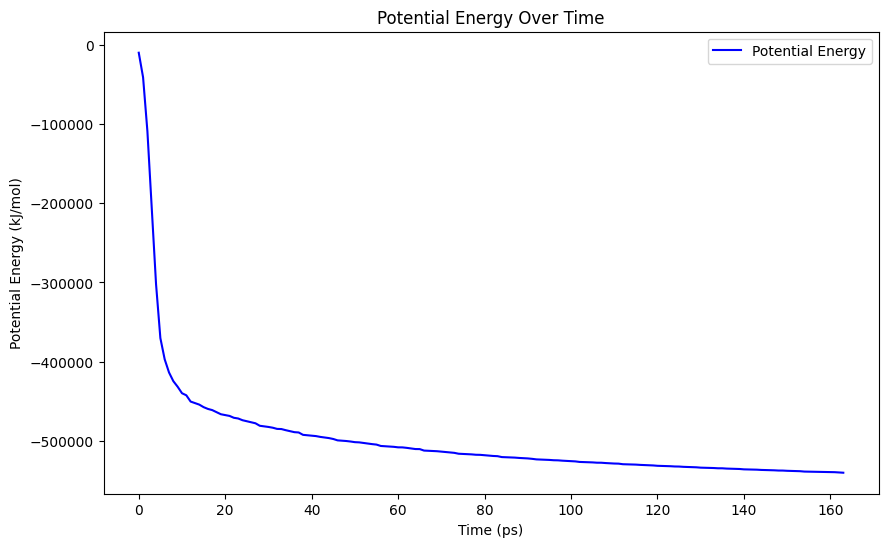

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

# Ensure plots are displayed inline in the notebook
%matplotlib inline

# Find the line where '@ s0 legend "Potential"' is located
with open('potential.xvg', 'r') as file:
    lines = file.readlines()

# Search for the line index containing '@ s0 legend "Potential"'
for i, line in enumerate(lines):
    if '@ s0 legend "Potential"' in line:
        data_start_index = i + 1  # Assuming data starts right after this line
        break

# Load the potential energy data starting from the identified line
data = pd.read_csv('potential.xvg', comment='@', delim_whitespace=True, header=None, skiprows=data_start_index)

# Assuming the first column is time and the second column is potential energy
time = data[0]
potential_energy = data[1]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(time, potential_energy, label='Potential Energy', color='b')
plt.title('Potential Energy Over Time')
plt.xlabel('Time (ps)')  # Change this label if necessary
plt.ylabel('Potential Energy (kJ/mol)')  # Change this label if necessary
plt.legend()
plt.show()


This script automatically creates an `NVT.mdp` file for **constant-volume (NVT) equilibration** of a protein–solvent system.  


In [34]:
# Define the content for the NVT.mdp file
mdp_content = """title                   = Nuclear receptor NVT equilibration 
define                  = -DPOSRES  ; position restrain the protein
; Run parameters
integrator              = md        ; leap-frog integrator
nsteps                  = 50000     ; 2 * 50000 = 100 ps
dt                      = 0.002     ; 2 fs
; Output control
nstxout                 = 500       ; save coordinates every 1.0 ps
nstvout                 = 500       ; save velocities every 1.0 ps
nstenergy               = 500       ; save energies every 1.0 ps
nstlog                  = 500       ; update log file every 1.0 ps
; Bond parameters
continuation            = no        ; first dynamics run
constraint_algorithm    = lincs     ; holonomic constraints 
constraints             = h-bonds   ; bonds involving H are constrained
lincs_iter              = 1         ; accuracy of LINCS
lincs_order             = 4         ; also related to accuracy
; Nonbonded settings 
cutoff-scheme           = Verlet    ; Buffered neighbor searching
ns_type                 = grid      ; search neighboring grid cells
nstlist                 = 10        ; 20 fs, largely irrelevant with Verlet
rcoulomb                = 1.0       ; short-range electrostatic cutoff (in nm)
rvdw                    = 1.0       ; short-range van der Waals cutoff (in nm)
DispCorr                = EnerPres  ; account for cut-off vdW scheme
; Electrostatics
coulombtype             = PME       ; Particle Mesh Ewald for long-range electrostatics
pme_order               = 4         ; cubic interpolation
fourierspacing          = 0.16      ; grid spacing for FFT
; Temperature coupling is on
tcoupl                  = V-rescale             ; modified Berendsen thermostat
tc-grps                 = Protein Non-Protein   ; two coupling groups - more accurate
tau_t                   = 0.1     0.1           ; time constant, in ps
ref_t                   = 310     310           ; reference temperature, one for each group, in K
; Pressure coupling is off
pcoupl                  = no        ; no pressure coupling in NVT
; Periodic boundary conditions
pbc                     = xyz       ; 3-D PBC
; Velocity generation
gen_vel                 = yes       ; assign velocities from Maxwell distribution
gen_temp                = 310       ; temperature for Maxwell distribution
gen_seed                = -1        ; generate a random seed
"""

# Write the content to a file called NVT.mdp in the working directory
with open('NVT.mdp', 'w') as file:
    file.write(mdp_content)

# Confirm the file was created
print("NVT.mdp file has been created in the working directory.")


NVT.mdp file has been created in the working directory.


This script loads the required modules, prepares the NVT input (`grompp`), runs the NVT equilibration (`mdrun`), and extracts the temperature profile (`gmx energy`).  


In [35]:
%%bash


# create gromacs input files for NVT equillibration
gmx_mpi grompp -f NVT.mdp -c b4NVT.gro -r b4NVT.gro -p protein.top -o NVT.tpr

# Run NVT equillibration
gmx_mpi mdrun -s NVT.tpr -o NVT.trr -c b4NPT.gro -g NVT.log -e NVT.edr

# Let's analyze the temperature progression
printf "16\n0\n" | gmx_mpi energy -f NVT.edr -o temperature.xvg


bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

Setting the LD random seed to 2141192141

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Setting gen_seed to -73400370

Velocities were taken from a Maxwell distribution at 310 K
Analysing residue names:
There are:   275    Protein residues
There are: 11153      Water residues
There are:     4        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.419 nm between atom 856 and 864

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 310 K

Calculated rlist for 1x1 atom pair-list as 1.034 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pair-list, to 1.000 nm, buffer size 0.000 nm

Note that mdrun will re

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ/Prep
Command line:
  gmx_mpi mdrun -s NVT.tpr -o NVT.trr -c b4NPT.gro -g NVT.log -e NVT.edr

Reading file NVT.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Changing nstlist from 10 to 100, rlist from 1 to 1.155


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the GPU
PME tasks will do all aspects on the GPU
Using 1 MPI proce


Statistics over 50001 steps [ 0.0000 through 100.0000 ps ], 1 data sets
All statistics are over 501 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Temperature                 310.054       0.18    2.36496    1.02859  (K)


/tmp/ipykernel_3694786/1380318588.py:18: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv('temperature.xvg', comment='@', delim_whitespace=True, header=None, skiprows=data_start_index)


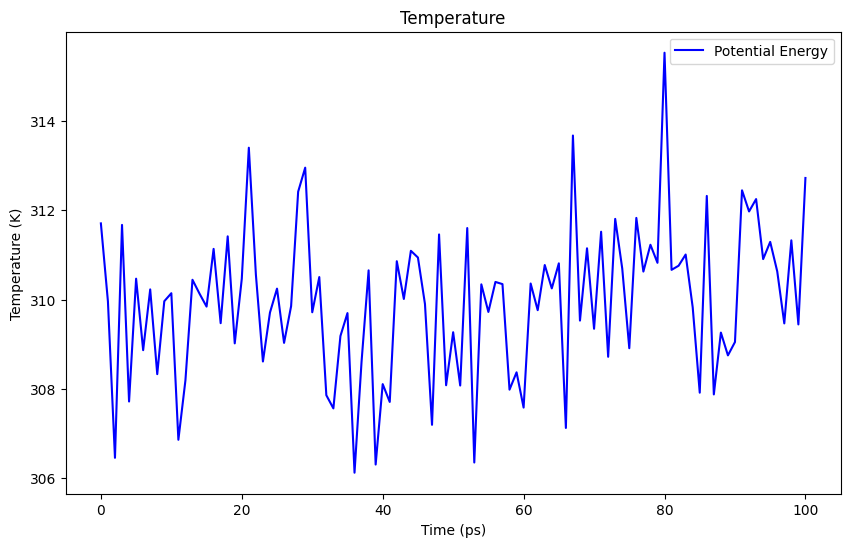

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

# Ensure plots are displayed inline in the notebook
%matplotlib inline

# Find the line where '@ s0 legend "Temperature"' is located
with open('temperature.xvg', 'r') as file:
    lines = file.readlines()

# Search for the line index containing '@ s0 legend "Potential"'
for i, line in enumerate(lines):
    if '@ s0 legend "Temperature"' in line:
        data_start_index = i + 1  # Assuming data starts right after this line
        break

# Load the potential energy data starting from the identified line
data = pd.read_csv('temperature.xvg', comment='@', delim_whitespace=True, header=None, skiprows=data_start_index)

# Assuming the first column is time and the second column is potential energy
time = data[0]
potential_energy = data[1]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(time, potential_energy, label='Potential Energy', color='b')
plt.title('Temperature')
plt.xlabel('Time (ps)')  # Change this label if necessary
plt.ylabel('Temperature (K)')  # Change this label if necessary
plt.legend()
plt.show()


This script creates an `NPT.mdp` file for 100 ps constant-pressure equilibration with position restraints, V-rescale thermostat, and isotropic pressure coupling enabled.  


In [37]:
# Define the content for the NPT.mdp file
mdp_content = """
title                   = OPLS Lysozyme NPT equilibration 
define                  = -DPOSRES  ; position restrain the protein
; Run parameters
integrator              = md        ; leap-frog integrator
nsteps                  = 50000     ; 2 * 50000 = 100 ps
dt                      = 0.002     ; 2 fs
; Output control
nstxout                 = 500       ; save coordinates every 1.0 ps
nstvout                 = 500       ; save velocities every 1.0 ps
nstenergy               = 500       ; save energies every 1.0 ps
nstlog                  = 500       ; update log file every 1.0 ps
; Bond parameters
continuation            = yes       ; Restarting after NVT 
constraint_algorithm    = lincs     ; holonomic constraints 
constraints             = h-bonds   ; bonds involving H are constrained
lincs_iter              = 1         ; accuracy of LINCS
lincs_order             = 4         ; also related to accuracy
; Nonbonded settings 
cutoff-scheme           = Verlet    ; Buffered neighbor searching
ns_type                 = grid      ; search neighboring grid cells
nstlist                 = 10        ; 20 fs, largely irrelevant with Verlet scheme
rcoulomb                = 1.0       ; short-range electrostatic cutoff (in nm)
rvdw                    = 1.0       ; short-range van der Waals cutoff (in nm)
DispCorr                = EnerPres  ; account for cut-off vdW scheme
; Electrostatics
coulombtype             = PME       ; Particle Mesh Ewald for long-range electrostatics
pme_order               = 4         ; cubic interpolation
fourierspacing          = 0.16      ; grid spacing for FFT
; Temperature coupling is on
tcoupl                  = V-rescale             ; modified Berendsen thermostat
tc-grps                 = Protein Non-Protein   ; two coupling groups - more accurate
tau_t                   = 0.1     0.1           ; time constant, in ps
ref_t                   = 310     310           ; reference temperature, one for each group, in K
; Pressure coupling is on
pcoupl                  = C-rescale     ; Pressure coupling on in NPT
pcoupltype              = isotropic             ; uniform scaling of box vectors
tau_p                   = 2.0                   ; time constant, in ps
ref_p                   = 1.0                   ; reference pressure, in bar
compressibility         = 4.5e-5                ; isothermal compressibility of water, bar^-1
refcoord_scaling        = com
; Periodic boundary conditions
pbc                     = xyz       ; 3-D PBC
; Velocity generation
gen_vel                 = no        ; Velocity generation is off
"""

# Write the content to a file called NVT.mdp in the working directory
with open('NPT.mdp', 'w') as file:
    file.write(mdp_content)

# Confirm the file was created
print("NPT.mdp file has been created in the working directory.")


NPT.mdp file has been created in the working directory.


This script loads the required modules, prepares the NPT input (`grompp`), runs the NPT equilibration (`mdrun`), and extracts the pressure profile (`gmx energy`).  


In [38]:
%%bash

# create gromacs input files for NPT equillibration
gmx_mpi grompp -f NPT.mdp -c b4NPT.gro -r b4NPT.gro -p protein.top -o NPT.tpr

# Run NPT equillibration
gmx_mpi mdrun -s NPT.tpr -o NPT.trr -c b4md.gro -g NPT.log -e NPT.edr

# Let's analyze the temperature progression
printf "18\n0\n" | gmx_mpi energy -f NPT.edr -o Pressure.xvg

bash: ml: line 1: syntax error: unexpected end of file
bash: error importing function definition for `ml'
bash: find_port: line 1: syntax error: unexpected end of file
bash: error importing function definition for `find_port'
bash: which: line 1: syntax error: unexpected end of file
bash: error importing function definition for `which'
bash: create_passwd: line 1: syntax error: unexpected end of file
bash: error importing function definition for `create_passwd'
bash: random_number: line 1: syntax error: unexpected end of file
bash: error importing function definition for `random_number'
bash: module: line 1: syntax error: unexpected end of file
bash: error importing function definition for `module'
bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
bash: error importing function definition for `setup_accre_software_stack'
bash: wait_until_port_used: line 1: syntax error: unexpected end of file
bash: error importing function definition for `wait_until_port_us

Setting the LD random seed to -269653649

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

The center of mass of the position restraint coord's is  3.461  4.117  3.381

The center of mass of the position restraint coord's is  3.461  4.117  3.381
Analysing residue names:
There are:   275    Protein residues
There are: 11153      Water residues
There are:     4        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.431 nm between atom 2047 and 2055

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 310 K

Calculated rlist for 1x1 atom pair-list as 1.034 nm, buffer size 0.034 nm

Set rlist, assuming 4x4 atom pa

                :-) GROMACS - gmx mdrun, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Reruns/6ONJ/Prep
Command line:
  gmx_mpi mdrun -s NPT.tpr -o NPT.trr -c b4md.gro -g NPT.log -e NPT.edr

Reading file NPT.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
GPU-aware MPI detected, but by default GROMACS will not make use the direct GPU communication capabilities of MPI. For improved performance try enabling the feature by setting the GMX_ENABLE_DIRECT_GPU_COMM environment variable.
Changing nstlist from 10 to 100, rlist from 1 to 1.155


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do (non-perturbed) short-ranged interactions on the GPU
PP task will update and constrain coordinates on the GPU
PME tasks will do all aspects on the GPU
Using 1 MPI proces


Statistics over 50001 steps [ 0.0000 through 100.0000 ps ], 1 data sets
All statistics are over 501 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Pressure                   0.203315         13    169.774   -6.81226  (bar)


/tmp/ipykernel_3694786/3138044334.py:18: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv('Pressure.xvg', comment='@', delim_whitespace=True, header=None, skiprows=data_start_index)


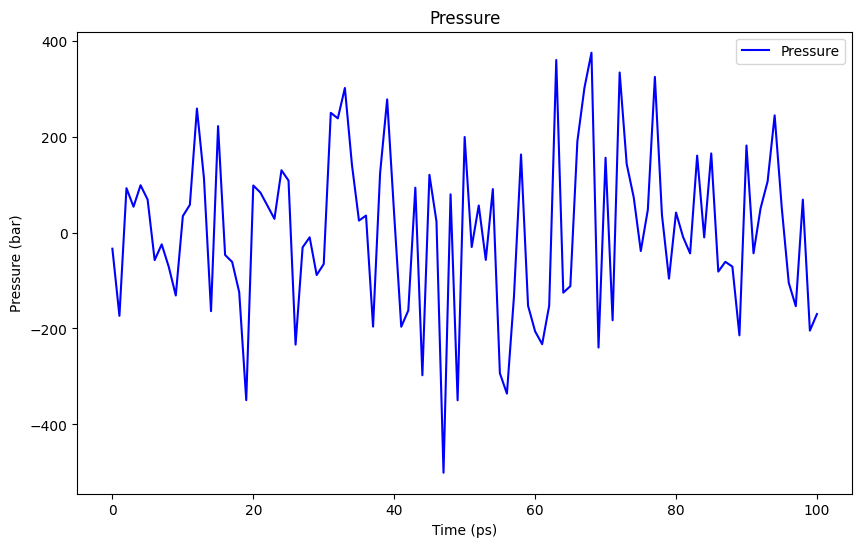

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

# Ensure plots are displayed inline in the notebook
%matplotlib inline

# Find the line where '@ s0 legend "Temperature"' is located
with open('Pressure.xvg', 'r') as file:
    lines = file.readlines()

# Search for the line index containing '@ s0 legend "Potential"'
for i, line in enumerate(lines):
    if '@ s0 legend "Pressure"' in line:
        data_start_index = i + 1  # Assuming data starts right after this line
        break

# Load the potential energy data starting from the identified line
data = pd.read_csv('Pressure.xvg', comment='@', delim_whitespace=True, header=None, skiprows=data_start_index)

# Assuming the first column is time and the second column is potential energy
time = data[0]
potential_energy = data[1]

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(time, potential_energy, label='Pressure', color='b')
plt.title('Pressure')
plt.xlabel('Time (ps)')  # Change this label if necessary
plt.ylabel('Pressure (bar)')  # Change this label if necessary
plt.legend()
plt.show()
